In [1]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys
import numpy as np, torch, matplotlib.pyplot as plt

PROJECT = os.path.expanduser("~/spline_flows")
FIG = os.path.join(PROJECT, "figures")
os.makedirs(FIG, exist_ok=True)
sys.path.insert(0, PROJECT)                  # so Python finds quadratic_spline.py
from quadratic_spline import QuadraticSpline

FPS = 30
d = np.load(os.path.join(PROJECT, "walk_windows_history8_horizon32_stride4.npz"))
Y_train = d["Y_train"]                       # (17813, 32, 29) future windows, radians
J_min, J_max = d["J_min"], d["J_max"]        # per-joint stats from training frames

def normalize(x):   return 2 * (x - J_min) / (J_max - J_min + 1e-6) - 1
def unnormalize(z): return (z + 1) / 2 * (J_max - J_min + 1e-6) + J_min
print(Y_train.shape)

(17813, 32, 29)


In [4]:
rng = np.random.default_rng(0)                    # fixed seed: same subset every run
idx = rng.choice(len(Y_train), size=2000, replace=False)
Y  = Y_train[idx]                                 # (2000, 32, 29), radians
Yn = torch.tensor(normalize(Y), dtype=torch.float32)

In [8]:
results = []
for K in [2, 4, 6, 10, 14]:
    spline = QuadraticSpline(nbSeg=K, nbDim=29, device="cpu")
    w, recon_n = spline.encode_trajectory(Yn)     # w: (2000, 29*(K+2)), recon_n: (2000, 32, 29)
    recon = unnormalize(recon_n.numpy())          # back to radians

    pos_err = np.sqrt(np.mean((recon - Y) ** 2))
    vel_true = np.diff(Y, axis=1) * FPS           # rad/frame -> rad/s
    print("typical joint speed (RMS):", np.sqrt(np.mean(vel_true ** 2)), "rad/s")
    vel_rec  = np.diff(recon, axis=1) * FPS
    vel_err  = np.sqrt(np.mean((vel_rec - vel_true) ** 2))

    results.append((K, 29 * (K + 2), pos_err, vel_err))
    print(f"K={K:2d}  numbers={29*(K+2):4d}  pos RMSE={pos_err:.4f} rad  vel RMSE={vel_err:.3f} rad/s")

typical joint speed (RMS): 1.144715038033048 rad/s
K= 2  numbers= 116  pos RMSE=0.0600 rad  vel RMSE=0.982 rad/s
typical joint speed (RMS): 1.144715038033048 rad/s
K= 4  numbers= 174  pos RMSE=0.0356 rad  vel RMSE=0.767 rad/s
typical joint speed (RMS): 1.144715038033048 rad/s
K= 6  numbers= 232  pos RMSE=0.0213 rad  vel RMSE=0.572 rad/s
typical joint speed (RMS): 1.144715038033048 rad/s
K=10  numbers= 348  pos RMSE=0.0087 rad  vel RMSE=0.330 rad/s
typical joint speed (RMS): 1.144715038033048 rad/s
K=14  numbers= 464  pos RMSE=0.0043 rad  vel RMSE=0.206 rad/s


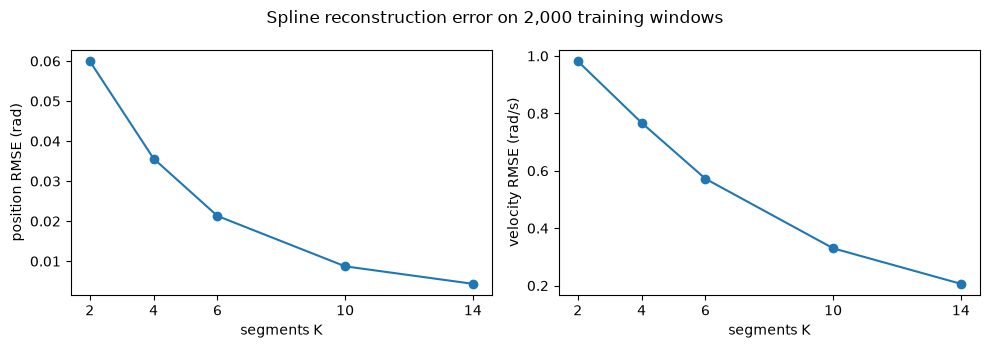

In [6]:
Ks, nums, pos, vel = zip(*results)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(Ks, pos, "o-"); ax[0].set_ylabel("position RMSE (rad)")
ax[1].plot(Ks, vel, "o-"); ax[1].set_ylabel("velocity RMSE (rad/s)")
for a in ax:
    a.set_xlabel("segments K"); a.set_xticks(Ks)
fig.suptitle("Spline reconstruction error on 2,000 training windows")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "spline_error_vs_K.png"), dpi=150)
plt.show()

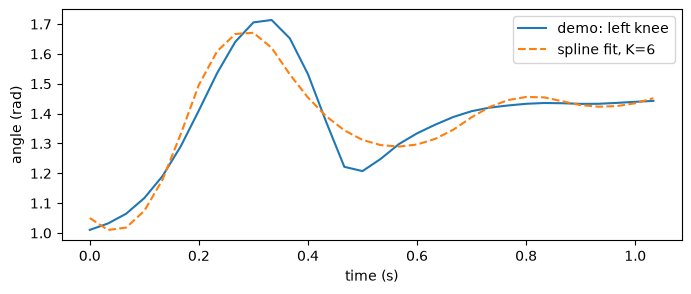

In [7]:
K = 6
spline = QuadraticSpline(nbSeg=K, nbDim=29, device="cpu")
_, recon_n = spline.encode_trajectory(Yn[:1])          # first window only
recon = unnormalize(recon_n.numpy())[0]                # (32, 29)
t = np.arange(32) / FPS
plt.figure(figsize=(8, 3))
plt.plot(t, Y[0, :, 3], label="demo: left knee")
plt.plot(t, recon[:, 3], "--", label=f"spline fit, K={K}")
plt.xlabel("time (s)"); plt.ylabel("angle (rad)"); plt.legend()
plt.savefig(os.path.join(FIG, "spline_fit_example.png"), dpi=150)
plt.show()